## Maps
Final maps for the README: fire hazard share by ZIP code, insurer-initiated non-renewal rates, and an interactive map

In [51]:
from pathlib import Path
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

clean = Path("../data/clean")
images = Path("../images")

zips = gpd.read_file(clean / "ca_zip_boundaries.gpkg")
counties = gpd.read_file(clean / "ca_counties.gpkg")
share = pd.read_csv(clean / "zip_fire_hazard_share.csv", dtype = {"zip": str})
cdi = pd.read_csv(clean / "cdi_nonrenewals_by_zip_year.csv", dtype = {"zip": str})

zips = zips.merge(share, on = "zip", how = "left")
zips["hazard_pct"] = zips["share_high_or_vh"] * 100
print(len(zips), zips.crs)

1802 EPSG:3310


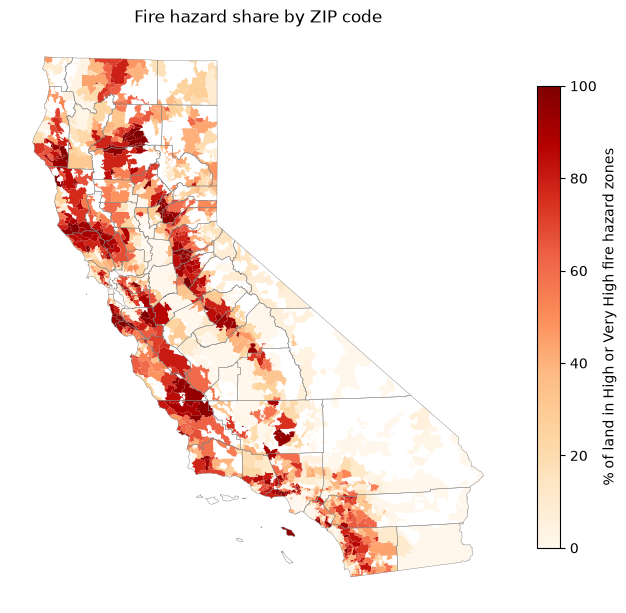

In [52]:
#plot map 1, the hazard share
#fig, ax creates the figure first, so every layer draws on the same ax
fig, ax = plt.subplots(figsize = (8, 10))
zips.plot(column = "hazard_pct", cmap = "OrRd", ax = ax, legend = True, legend_kwds = {"label": "% of land in High or Very High fire hazard zones", "shrink": 0.6})
counties.boundary.plot(ax = ax, color = "grey", linewidth = 0.3)

ax.set_title("Fire hazard share by ZIP code")
ax.set_axis_off()
plt.savefig(images / "hazard_share_map.png", dpi = 150, bbox_inches = "tight")

In [53]:
#each ZIP code's insurer-initiated rate, 2019-2021, the period after the gap opened
#combining three years of counts makes each ZIP code's rate more stable than any single year
#we set the low cutoff to 300, or 100 per year, matching notebook 1
recent = cdi[(cdi["source"] == "2015-2021 file") & (cdi["year"].between(2019, 2021))]
zip_rates = recent.groupby("zip")[["nonrenewed_insurer", "up_for_renewal"]].sum().reset_index()
zip_rates["insurer_rate_19_21"] = zip_rates["nonrenewed_insurer"] / zip_rates["up_for_renewal"]
zip_rates["low_volume"] = zip_rates["up_for_renewal"] < 300

zips = zips.merge(zip_rates[["zip", "insurer_rate_19_21", "up_for_renewal", "low_volume"]], on = "zip", how = "left")
zips["insurer_rate_19_21"].describe()

count    1785.000000
mean        0.037515
std         0.041296
min         0.000000
25%         0.017310
50%         0.026068
75%         0.042714
max         0.666667
Name: insurer_rate_19_21, dtype: float64

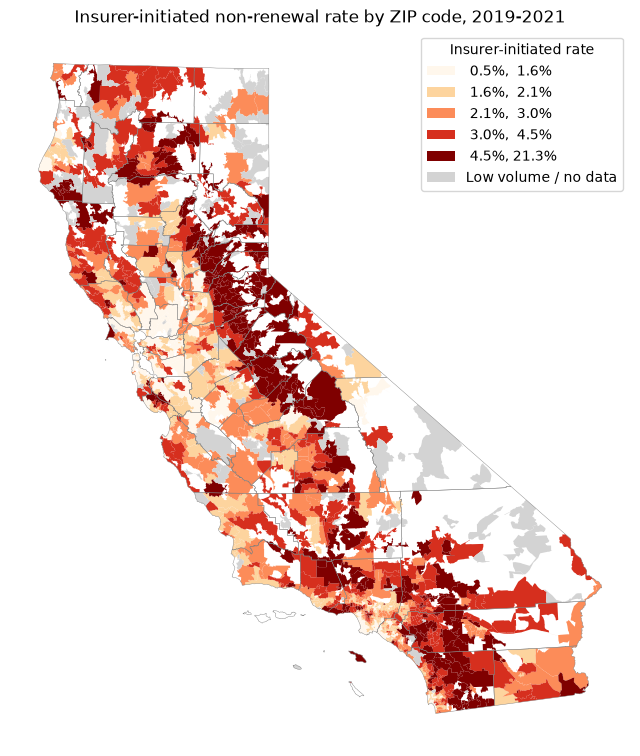

In [54]:
#plot map 2, the non-renewal rate (with low-volume areas greyed out)
#we use missing_kwds to make blanking the low-volume rates grey
#!= False catches both flagged ZIP codes and ZIP codes with no CDI data
#scheme=... splits the ZIP codes into five equal sized colored groups
#since rates are skewed, a plain color scale would make everything look a similar shade
#fmt shows the legend values as percentages
plot_zips = zips.copy()
plot_zips.loc[plot_zips["low_volume"] != False, "insurer_rate_19_21"] = None

fig, ax = plt.subplots(figsize = (8, 10))
plot_zips.plot(column = "insurer_rate_19_21", cmap = "OrRd", scheme = "quantiles", k = 5, ax = ax,
               legend = True, legend_kwds = {"title": "Insurer-initiated rate", "fmt": "{:.1%}"},
               missing_kwds = {"color": "lightgrey", "label": "Low volume / no data"})
counties.boundary.plot(ax = ax, color = "grey", linewidth = 0.3)

ax.set_title("Insurer-initiated non-renewal rate by ZIP code, 2019-2021")
ax.set_axis_off()
plt.savefig(images / "insurer_rate_map.png", dpi = 150, bbox_inches = "tight")

In [55]:
#prepare the web layer for interactive map
#simplify() removes boundary points within a certain length (meters), enabling HTML files to load faster
web = zips[["zip", "share_high_or_vh", "hazard_pct", "insurer_rate_19_21", "low_volume", "geometry"]].copy()
web["geometry"] = web.geometry.simplify(100)

web["Hazard share"] = web["share_high_or_vh"].map(
    lambda x: f"{x:.0%}" if pd.notna(x) else "No data")
web["Insurer rate 2019-21"] = web.apply(
    lambda r: f"{r['insurer_rate_19_21']:.1%}" if r["low_volume"] == False else "Low volume / no data",
    axis=1)

In [56]:
#build and save map
m = web.explore(
    column = "hazard_pct",
    cmap = "OrRd",
    tooltip = ["zip", "Hazard share", "Insurer rate 2019-21"],
    tooltip_kwds = {"aliases": ["ZIP code", "Hazard share", "Insurer rate 2019-21"]},
    tiles = "Esri.WorldGrayCanvas",
    style_kwds = {"weight": 0.3, "color": "grey", "fillOpacity": 0.75},
    legend_kwds = {"caption": "% of land in High or Very High fire hazard zones"},)
m.save("../wildfire_map.html")

size_mb = Path("../wildfire_map.html").stat().st_size / 1e6
print(f"{size_mb:.1f} MB")

6.2 MB


In [57]:
#confirming rates for Pacific Palisades and Malibu
#Altadena's rate was below the median before the Eaton fire
zips.set_index("zip").loc[["90272", "91001", "90265", "90012"], ["share_high_or_vh", "insurer_rate_19_21", "low_volume"]]

,share_high_or_vh,insurer_rate_19_21,low_volume
zip,,,
90272,0.999954,0.037929,False
91001,0.430423,0.023289,False
90265,0.799689,0.064712,False
90012,0.515793,0.016772,False


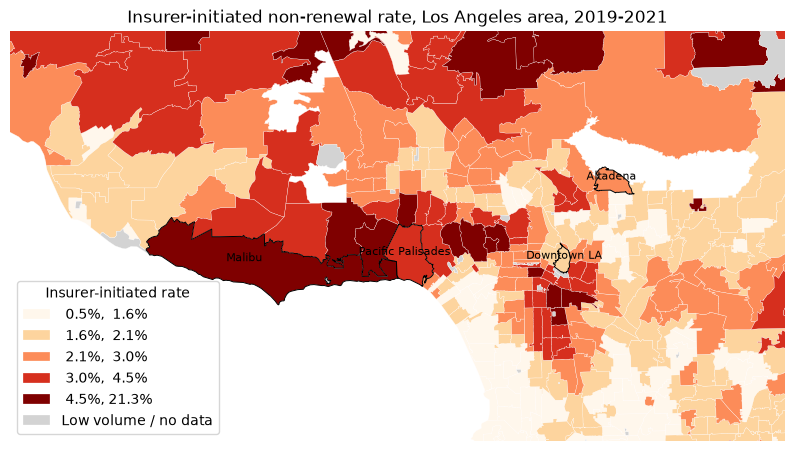

In [ ]:
#close-up of LA's insurer-rate map from map 2
#emphasis on LA since I live here
#want to show that Pacific Palisades and Malibu both had high hazard shares and elevated non-renewals before the fires
labels = {"90265": "Malibu", "90272": "Pacific Palisades", "91001": "Altadena", "90012": "Downtown LA"}
la_zips = ["90265", "90272", "90012", "91001", "91101", "91107"]

fig, ax = plt.subplots(figsize=(10, 7))
plot_zips.plot(column = "insurer_rate_19_21", cmap = "OrRd", scheme = "quantiles", k = 5, ax = ax, edgecolor = "white", linewidth = 0.2, legend = True,
            legend_kwds = {"title": "Insurer-initiated rate", "fmt": "{:.1%}", "loc": "lower left"},
            missing_kwds = {"color": "lightgrey", "label": "Low volume / no data"})

spots = plot_zips[plot_zips["zip"].isin(labels)]
spots.boundary.plot(ax = ax, color = "black", linewidth = 0.7)
for _, row in spots.iterrows():
    pt = row.geometry.representative_point()
    ax.annotate(labels[row["zip"]], xy = (pt.x, pt.y), ha = "center", fontsize = 8)

xmin, ymin, xmax, ymax = plot_zips[plot_zips["zip"].isin(la_zips)].total_bounds
pad = 25000
ax.set_xlim(xmin - pad, xmax + pad)
ax.set_ylim(ymin - pad, ymax + pad)

ax.set_title("Insurer-initiated non-renewal rate, Los Angeles area, 2019-2021")
ax.set_axis_off()
plt.savefig(images / "insurer_rate_map_la.png", dpi = 150, bbox_inches = "tight")

Saved three static maps (statewide fire hazard share, statewide insurer-initiated rate for 2019 to 2021, and an LA close-up) and an interactive map as wildfire_map.html. ZIP codes with fewer than 300 policies up for renewal over 2019 to 2021 are greyed out, and the darkest non-renewal areas line up with the highest hazard areas along the Sierra foothills and Southern California mountains.